In [ ]:
# Library
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from google.colab import drive
from skimage.metrics import structural_similarity
from torch.utils.data import ConcatDataset, DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 128
LATENT_DIM = 64
LEARNING_RATE = 0.001
EPOCHS = 20
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [2]:
# CP
from pathlib import Path

USE_GOOGLE_DRIVE = True

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/Model_Comparison"
    )
else:
    PROJECT_DIR = Path(".")

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "vanilla_ae"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Use Google Drive:", USE_GOOGLE_DRIVE)
print("Project Directory:", PROJECT_DIR)
print("Checkpoint Directory:", CHECKPOINT_DIR)
print("Output Directory:", OUTPUT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Use Google Drive: True
Project Directory: /content/drive/MyDrive/Model_Comparison
Checkpoint Directory: /content/drive/MyDrive/Model_Comparison/checkpoints
Output Directory: /content/drive/MyDrive/Model_Comparison/outputs/vanilla_ae


In [ ]:
# Dataset
transform = transforms.ToTensor()
train_original = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
test_original = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)
full_dataset = ConcatDataset([train_original, test_original])
train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, [56000, 7000, 7000],
    generator=torch.Generator().manual_seed(SEED)
)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
print("Train / validation / test:", len(train_dataset), len(val_dataset), len(test_dataset))

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 176kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.13MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.62MB/s]

Train / validation / test: 56000 7000 7000


In [ ]:
# Vanilla AE -> Architecture
class VanillaAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstructed = self.decoder(z)
        return reconstructed.view(-1, 1, 28, 28)

vanilla_ae = VanillaAE(latent_dim=LATENT_DIM).to(DEVICE)
print(vanilla_ae)

VanillaAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)


In [ ]:
# Vanilla AE -> Training
criterion = nn.MSELoss()
optimizer = optim.Adam(vanilla_ae.parameters(), lr=LEARNING_RATE)
train_losses, val_losses, epoch_times = [], [], []
best_val_loss = float("inf")
best_vanilla_ae_state = None

for epoch in range(EPOCHS):
    start_time = time.perf_counter()
    vanilla_ae.train()
    total_train_loss = 0.0

    for images, _ in train_loader:
        images = images.to(DEVICE)
        optimizer.zero_grad()
        reconstructed = vanilla_ae(images)
        loss = criterion(reconstructed, images)
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item() * images.size(0)

    avg_train_loss = total_train_loss / len(train_dataset)
    vanilla_ae.eval()
    total_val_loss = 0.0

    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(DEVICE)
            reconstructed = vanilla_ae(images)
            loss = criterion(reconstructed, images)
            total_val_loss += loss.item() * images.size(0)

    avg_val_loss = total_val_loss / len(val_dataset)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    epoch_time = time.perf_counter() - start_time
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    epoch_times.append(epoch_time)

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_vanilla_ae_state = {
            key: value.detach().cpu().clone()
            for key, value in vanilla_ae.state_dict().items()
        }

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {avg_train_loss:.6f} | "
        f"Val Loss: {avg_val_loss:.6f} | "
        f"Time: {epoch_time:.2f}s"
    )

vanilla_ae.load_state_dict(best_vanilla_ae_state)
print("Best Validation Loss:", f"{best_val_loss:.6f}")
print("Average Epoch Time:", f"{np.mean(epoch_times):.2f}s")

checkpoint_path = CHECKPOINT_DIR / "vanilla_ae.pt"
torch.save(best_vanilla_ae_state, checkpoint_path)
print("Saved checkpoint:", checkpoint_path)

pd.DataFrame({
    "epoch": range(1, EPOCHS + 1),
    "train_loss": train_losses,
    "val_loss": val_losses,
    "epoch_time_s": epoch_times
}).to_csv(OUTPUT_DIR / "loss_history.csv", index=False)

Epoch [1/20] | Train Loss: 0.031825 | Val Loss: 0.018624 | Time: 8.70s
Epoch [2/20] | Train Loss: 0.016539 | Val Loss: 0.015599 | Time: 7.69s
Epoch [3/20] | Train Loss: 0.013942 | Val Loss: 0.013260 | Time: 7.99s
Epoch [4/20] | Train Loss: 0.012385 | Val Loss: 0.011948 | Time: 7.25s
Epoch [5/20] | Train Loss: 0.011286 | Val Loss: 0.011088 | Time: 7.89s
Epoch [6/20] | Train Loss: 0.010505 | Val Loss: 0.010347 | Time: 7.16s
Epoch [7/20] | Train Loss: 0.009855 | Val Loss: 0.009888 | Time: 7.62s
Epoch [8/20] | Train Loss: 0.009386 | Val Loss: 0.009437 | Time: 7.31s
Epoch [9/20] | Train Loss: 0.008968 | Val Loss: 0.009017 | Time: 7.43s
Epoch [10/20] | Train Loss: 0.008616 | Val Loss: 0.008742 | Time: 7.58s
Epoch [11/20] | Train Loss: 0.008325 | Val Loss: 0.008495 | Time: 7.31s
Epoch [12/20] | Train Loss: 0.008051 | Val Loss: 0.008209 | Time: 7.96s
Epoch [13/20] | Train Loss: 0.007824 | Val Loss: 0.007959 | Time: 6.86s
Epoch [14/20] | Train Loss: 0.007630 | Val Loss: 0.007797 | Time: 7.84s
E

In [ ]:
# Vanilla AE -> Test Eval
vanilla_ae.eval()
total_squared_error = 0.0
total_pixels = 0
psnr_values, ssim_values = [], []

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(DEVICE)
        reconstructed = vanilla_ae(images)
        squared_error = (reconstructed - images) ** 2
        total_squared_error += squared_error.sum().item()
        total_pixels += images.numel()
        mse_per_image = squared_error.mean(dim=(1, 2, 3))
        psnr_batch = 10 * torch.log10(1.0 / mse_per_image.clamp_min(1e-10))
        psnr_values.extend(psnr_batch.cpu().numpy())

        original_np = images.cpu().numpy()
        reconstructed_np = reconstructed.cpu().numpy()
        for i in range(len(images)):
            score = structural_similarity(
                original_np[i, 0], reconstructed_np[i, 0], data_range=1.0
            )
            ssim_values.append(score)

test_mse = total_squared_error / total_pixels
test_psnr = float(np.mean(psnr_values))
test_ssim = float(np.mean(ssim_values))

print("Vanilla AE Test Results")
print(f"Test MSE  : {test_mse:.6f}")
print(f"Test PSNR : {test_psnr:.4f}")
print(f"Test SSIM : {test_ssim:.6f}")

pd.DataFrame([{
    "model": "Vanilla AE", "test_mse": test_mse,
    "test_psnr": test_psnr, "test_ssim": test_ssim,
    "best_val_loss": best_val_loss,
    "mean_epoch_time_s": float(np.mean(epoch_times)),
    "latent_dim": LATENT_DIM, "epochs": EPOCHS, "seed": SEED
}]).to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)

Vanilla AE Test Results
Test MSE  : 0.007078
Test PSNR : 22.5646
Test SSIM : 0.815838


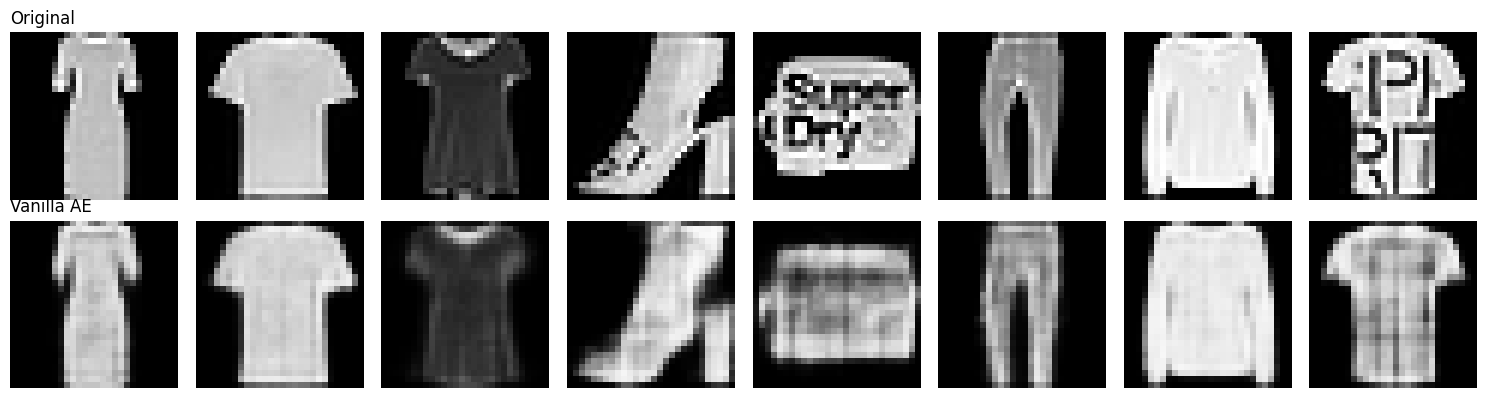

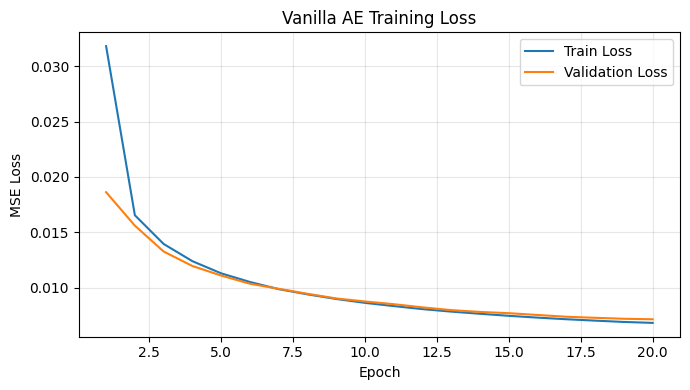

Saved images and CSV files to: /content/drive/MyDrive/Model_Comparison/outputs/vanilla_ae


In [ ]:
# Vanilla AE -> Reconstruct
vanilla_ae.eval()
comparison_images, comparison_labels = next(iter(test_loader))
comparison_images = comparison_images[:8].to(DEVICE)
with torch.no_grad():
    comparison_reconstructed = vanilla_ae(comparison_images)

fig, axes = plt.subplots(2, 8, figsize=(15, 4))
for i in range(8):
    axes[0, i].imshow(comparison_images[i, 0].cpu(), cmap="gray", vmin=0, vmax=1)
    axes[1, i].imshow(comparison_reconstructed[i, 0].cpu(), cmap="gray", vmin=0, vmax=1)
    for row in range(2):
        axes[row, i].axis("off")
axes[0, 0].set_title("Original", loc="left")
axes[1, 0].set_title("Vanilla AE", loc="left")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "reconstruction.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, EPOCHS + 1), train_losses, label="Train Loss")
ax.plot(range(1, EPOCHS + 1), val_losses, label="Validation Loss")
ax.set(xlabel="Epoch", ylabel="MSE Loss", title="Vanilla AE Training Loss")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "training_loss.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved images and CSV files to:", OUTPUT_DIR)